# U-Net assignment: sanity check, depth, loss, and augmentation

Run `dataPrepare.ipynb` first, then run these cells in order. Shared code lives in `data.py`, `model.py`, and `main.py`. This is a learning implementation: inspect the masks, understand each comparison, and write your own interpretation of measured results.

The 80/20 split uses `sklearn.model_selection.train_test_split` with seed 42. Of 936 pairs, 748 form the development pool and 188 are held out for testing. A further 75 development pairs form validation, leaving 673 for optimization. Depth and checkpoints are selected with validation data, not test data.

**Label audit:** The local masks store only IDs 0/1/2. A closely matching [Tobacco Aerial Dataset](https://data.mendeley.com/datasets/5dpc5gbgpz/2) documents 0=background, 1=crop, 2=weed, including a 936-image campaign at 480x352 with the same folder layout. This is a provisional match, not proof of the local archive identity. Its crop is tobacco, so do not claim wheat identity without dataset confirmation. Override CLASS_NAMES if your instructor supplies the mapping.


In [7]:
import os, sys, subprocess
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Copy main.py, data.py, model.py and the dataset into this Drive folder.
    PROJECT_DIR = Path('/content/drive/MyDrive/unet')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'scikit-learn>=1.4,<2', 'Pillow', 'matplotlib'])
    if not (PROJECT_DIR / 'main.py').exists():
        raise FileNotFoundError('Set PROJECT_DIR to the Drive folder containing main.py, data.py, model.py')
    os.chdir(PROJECT_DIR)
    if str(PROJECT_DIR) not in sys.path:
        sys.path.insert(0, str(PROJECT_DIR))
else:
    PROJECT_DIR = Path.cwd()
print('Project:', PROJECT_DIR)
print('Python:', sys.executable)


Project: e:\AamadNaseem\MSAIEngineering\2.SemesterFall2026\DeepLearning\unet
Python: e:\AamadNaseem\MSAIEngineering\2.SemesterFall2026\DeepLearning\unet\.venv\Scripts\python.exe


In [8]:
import json
from copy import deepcopy
from datetime import datetime
from types import SimpleNamespace
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from data import prepare_dataset, make_dataset, augment_pair
from main import prepare_run, run_training, run_experiments, configure_gpu

REQUIRE_GPU = True
GPUS = configure_gpu(require_gpu=REQUIRE_GPU)
print('Training GPUs:', GPUS)

DATASET = Path('data/936')
SEED = 42
IMAGE_SIZE = 128
BASE_FILTERS = 16  # Same standard U-Net topology, scaled width. Use 64 for canonical width.
BATCH_SIZE = 4
LEARNING_RATE = 1e-3
DEPTHS = (2,3,4,5)  # Number of pooling/upsampling levels; standard U-Net uses 4.
EPOCHS = 20  # Equal budget for every comparative experiment.
SANITY_EPOCHS = 300
SANITY_IMAGES = 5
DICE_WEIGHT = 1.0
DEPTH_TOLERANCE = 0.005
# Fill these only from verified dataset documentation; the masks store IDs only.
CLASS_NAMES = ['background', 'crop (provisional)', 'weed (provisional)']
RUN_ROOT = Path('runs') / ('assignment_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
RUN_ROOT.mkdir(parents=True,exist_ok=False)
base_args = SimpleNamespace(dataset=DATASET, limit=None, epochs=EPOCHS,
    size=IMAGE_SIZE, batch_size=BATCH_SIZE, base_filters=BASE_FILTERS,
    learning_rate=LEARNING_RATE, dropout_rate=0.5, depth=4, loss_mode='cce',
    dice_weight=DICE_WEIGHT, augmentation=False, seed=SEED, class_names=CLASS_NAMES,
    output=RUN_ROOT/'experiments', require_gpu=REQUIRE_GPU)
print('TensorFlow:',tf.__version__, 'Devices:',tf.config.list_physical_devices())


ImportError: cannot import name 'configure_gpu' from 'main' (e:\AamadNaseem\MSAIEngineering\2.SemesterFall2026\DeepLearning\unet\main.py)

## 1. Inspect the fixed split and overfit a few training images

The sanity run uses only five development-training images. It must not be reported as held-out performance. Compare its masks and class Dice before proceeding.


In [ ]:
images,masks,manifest = prepare_dataset(DATASET,None,seed=SEED)
if len(images) != 936:
    raise ValueError('The assignment requires 936 image/mask pairs')
print('Split:',{k:len(v) for k,v in manifest.items()})
assert not (set(manifest['train']) & set(manifest['test']))
assert not (set(manifest['validation']) & set(manifest['test']))
sanity_args=deepcopy(base_args)
sanity_args.limit=SANITY_IMAGES
sanity_args.epochs=SANITY_EPOCHS
sanity_args.dropout_rate=0.0
sanity_args.output=RUN_ROOT/'sanity'
sanity_metrics=run_training(sanity_args)
print('Sanity macro Dice:',sanity_metrics['macro_dice'])
if sanity_metrics['macro_dice'] < 0.9:
    print('Not yet fully overfit: inspect predictions and, if needed, increase SANITY_EPOCHS before comparing full runs.')


Split: {'train': 673, 'validation': 75, 'test': 188}

Dataset split: {'train_batches': 2, 'validation_batches': 2}
Parameters: 1941139 Hardware: ["PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"]
Epoch 1/300
2/2 - 4s - 2s/step - accuracy: 0.2901 - loss: 1.2439 - val_accuracy: 0.5811 - val_loss: 0.9931 - learning_rate: 0.0010
Epoch 2/300
2/2 - 0s - 82ms/step - accuracy: 0.5846 - loss: 1.0118 - val_accuracy: 0.5509 - val_loss: 0.9934 - learning_rate: 0.0010
Epoch 3/300
2/2 - 0s - 146ms/step - accuracy: 0.5707 - loss: 0.9857 - val_accuracy: 0.6140 - val_loss: 0.9260 - learning_rate: 0.0010
Epoch 4/300
2/2 - 0s - 140ms/step - accuracy: 0.6150 - loss: 0.9114 - val_accuracy: 0.6185 - val_loss: 0.8910 - learning_rate: 0.0010
Epoch 5/300
2/2 - 0s - 142ms/step - accuracy: 0.6187 - loss: 0.9090 - val_accuracy: 0.6209 - val_loss: 0.8837 - learning_rate: 0.0010
Epoch 6/300
2/2 - 0s - 85ms/step - accuracy: 0.6209 - loss: 0.8756 - val_accuracy: 0.6210 - val_loss: 0.8920 - learning_

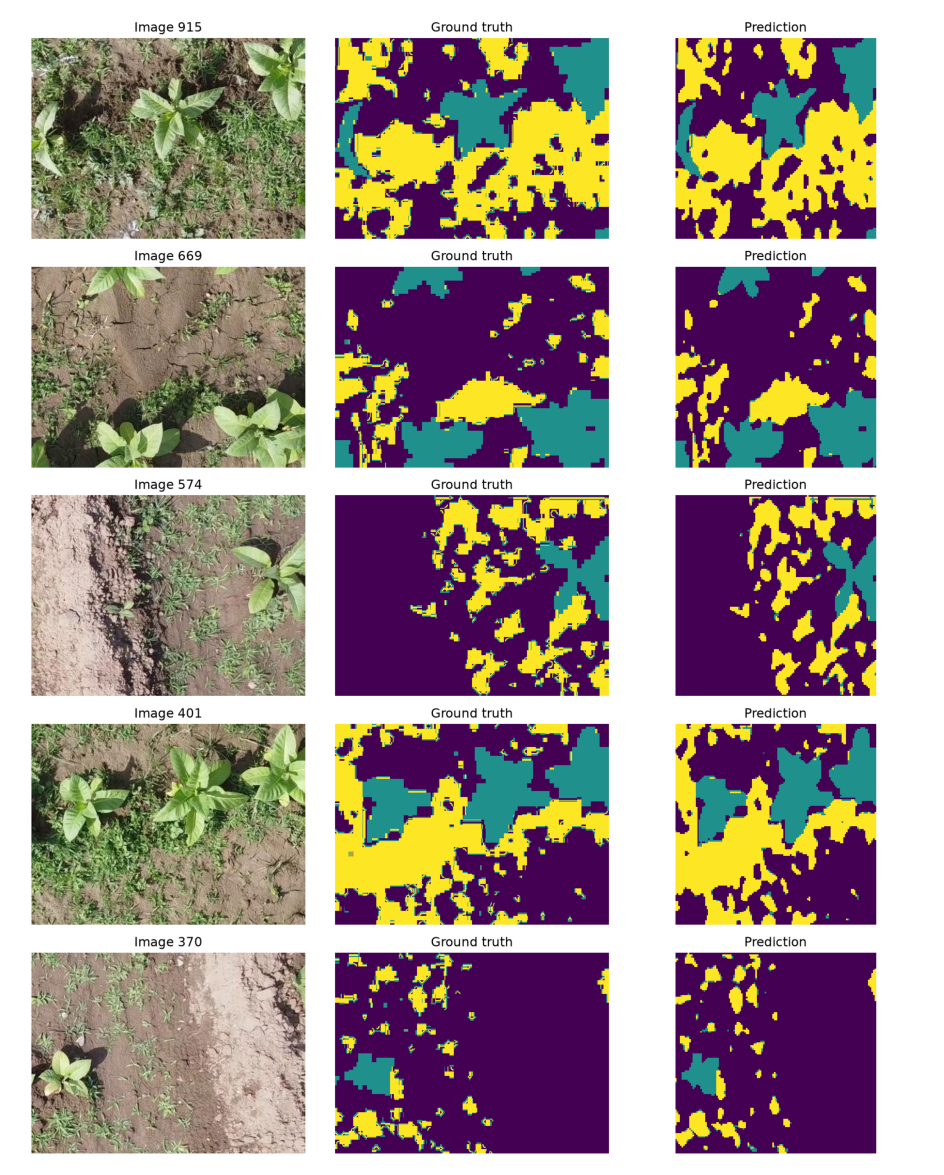

In [ ]:
plt.figure(figsize=(12,15))
plt.imshow(plt.imread(RUN_ROOT/'sanity'/'prediction_comparison.png'))
plt.axis('off'); plt.show()


## 2. Inspect synchronized augmentation

Flips and 90-degree rotations use the same transformation for image and mask. Brightness is changed only for photographs. Masks remain integer IDs until one-hot encoding. Validation and test data are never augmented.


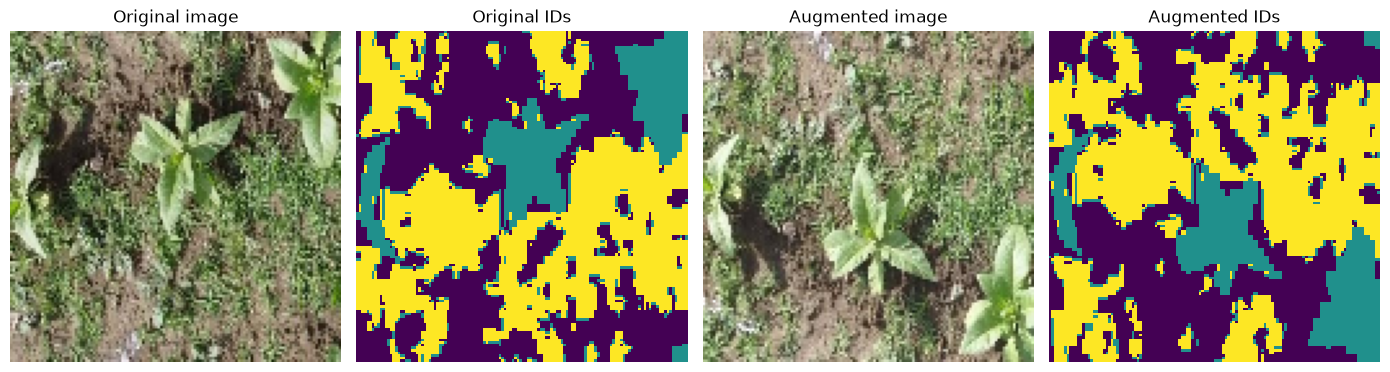

In [ ]:
sample = make_dataset(images,masks,manifest['train'][:1],size=IMAGE_SIZE,batch_size=1)
x,y=next(iter(sample))
aug_x,aug_y=augment_pair(x[0],y[0],tf.constant([SEED,7],tf.int32))
fig,axes=plt.subplots(1,4,figsize=(14,4))
for axis,item,title in zip(axes,[x[0],y[0],aug_x,aug_y],['Original image','Original IDs','Augmented image','Augmented IDs']):
    if item.shape.rank==2: axis.imshow(item,cmap='viridis',vmin=0,vmax=2,interpolation='nearest')
    else: axis.imshow(item)
    axis.set_title(title); axis.axis('off')
plt.tight_layout(); plt.show()


## 3. Run the depth study and controlled loss/augmentation comparisons

Each depth gets the same seed, width, data split, optimizer, and epoch budget. Depth is the number of encoder pooling and decoder upsampling levels. Choose the smallest depth whose validation macro Dice is within 0.005 of the best. This is a measured tradeoff, not a predetermined answer.

Then train a 2x2 comparison at that fixed depth: CCE / CCE+Dice, each without / with augmentation. The differentiable loss is $L=CCE+\lambda(1-\overline{Dice}_{soft})$. Soft Dice uses probabilities during training; the reported Dice uses argmax class IDs and `sklearn.metrics.f1_score`.

This cell runs eight full-dataset trainings by default and may take substantial time. Use Colab GPU. Reports contain actual measured scores and signed differences only after execution.


In [ ]:
results,selected_depth=run_experiments(base_args,depths=DEPTHS,depth_tolerance=DEPTH_TOLERANCE)
print('Selected levels:',selected_depth)


Experiment: depth_2
Dataset split: {'train_batches': 169, 'validation_batches': 19}
Parameters: 117075 Hardware: ["PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"]
Epoch 1/20
169/169 - 7s - 44ms/step - accuracy: 0.7585 - loss: 0.5791 - val_accuracy: 0.8741 - val_loss: 0.3485 - learning_rate: 0.0010
Epoch 2/20
169/169 - 5s - 29ms/step - accuracy: 0.8846 - loss: 0.3131 - val_accuracy: 0.8875 - val_loss: 0.3080 - learning_rate: 0.0010
Epoch 3/20
169/169 - 5s - 28ms/step - accuracy: 0.8999 - loss: 0.2727 - val_accuracy: 0.9022 - val_loss: 0.2630 - learning_rate: 0.0010
Epoch 4/20
169/169 - 5s - 29ms/step - accuracy: 0.9033 - loss: 0.2617 - val_accuracy: 0.9055 - val_loss: 0.2554 - learning_rate: 0.0010
Epoch 5/20
169/169 - 5s - 30ms/step - accuracy: 0.9074 - loss: 0.2491 - val_accuracy: 0.9064 - val_loss: 0.2485 - learning_rate: 0.0010
Epoch 6/20
169/169 - 5s - 30ms/step - accuracy: 0.9077 - loss: 0.2483 - val_accuracy: 0.9098 - val_loss: 0.2411 - learning_rate: 0.0010
Ep

KeyboardInterrupt: 

## 4. Read the measured results and write your discussion

Compare per-class, macro, and foreground Dice; explain the parameter/time tradeoff and any underfitting/overfitting. Report that depth was chosen with validation and that this is a single fixed-seed experiment. Do not treat the five-image sanity scores as test results.


In [ ]:
from IPython.display import Markdown, display
display(Markdown((base_args.output/'experiment_report.md').read_text()))
print('Performance differences:',json.loads((base_args.output/'performance_differences.json').read_text()))
for row in results:
    print(row['experiment'],dict(zip(CLASS_NAMES,row['dice_by_class_id'])))
# The last factorial run uses CCE+Dice with augmentation.
plt.figure(figsize=(12,15))
plt.imshow(plt.imread(base_args.output/'cce_dice_aug_1'/'prediction_comparison.png'))
plt.axis('off'); plt.show()
print('Reports, checkpoints and predictions:',RUN_ROOT.resolve())


In [ ]:
depth_rows=[row for row in results if row['experiment'].startswith('depth_')]
fig,axes=plt.subplots(1,3,figsize=(14,4))
levels=[row['depth'] for row in depth_rows]
for axis,key,title in zip(axes,['macro_dice','parameter_count','training_seconds'],
    ['Validation macro Dice','Trainable parameters','Training seconds']):
    axis.plot(levels,[row[key] for row in depth_rows],marker='o')
    axis.set_xlabel('Encoder/decoder levels'); axis.set_title(title); axis.set_xticks(levels)
plt.tight_layout(); plt.show()
fig.savefig(base_args.output/'depth_comparison.png',dpi=140)
ablations=[row for row in results if not row['experiment'].startswith('depth_')]
fig,axis=plt.subplots(figsize=(9,4))
axis.bar([row['experiment'] for row in ablations],[row['macro_dice'] for row in ablations])
axis.set_ylabel('Held-out macro Dice'); axis.set_ylim(0,1); axis.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.show()
fig.savefig(base_args.output/'loss_augmentation_comparison.png',dpi=140)
